# HeartPost — heart-disease triage for rural clinics
**Track:** AI + Health · Veritas AI International High School Hackathon 2026

> **This project is a prototype and is not medical advice.**

**User.** A nurse practitioner or physician assistant at a small rural health clinic in the United States. Nearly half of US counties have no practicing cardiologist (86% of rural counties do not), and patients there drive about 87 miles round trip to see one. When an adult comes in with chest pain or for a check-up, the clinician must decide: *send this person to the cardiologist now, schedule a referral, or follow up at the clinic?*

**Our question.** Classic heart-disease models use 13 measurements, but 4–6 of them (exercise stress test, fluoroscopy, thallium scan) only exist in a cardiology centre — exactly the place the patient hasn't reached yet. So we ask:
1. Can a model that uses **only what a small rural clinic can measure** catch heart disease **in hospitals it has never seen**?
2. Does it work **equally well for women and men**, and for different ages? If not, can we fix it?

**Data.** UCI Heart Disease: 4 hospitals (Cleveland USA, Budapest Hungary, Zurich/Basel Switzerland, Long Beach VA USA), 920 patients, all public. We train **only on Cleveland** and use the other three hospitals as a never-seen external test.

Notebook outline: 1 Data → 2 Feature tiers → 3 Baselines & models → 4 External test → 5 Why the "full" model breaks → 6 Fairness & fix → 7 Triage zones → 8 Where it fails → 9 Robustness → 10 Export for the app.

In [1]:
# Setup. Works in Google Colab or locally. Only standard libraries (pandas, numpy, scikit-learn, matplotlib).
import os, json, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, confusion_matrix
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)
SEED = 42
# One visual language for every chart (same colours as the app): pen-ink blue, ECG red, zone green/amber
INK, RED, GREEN, AMBER, GREY = "#1c2b4a", "#b3261e", "#2d7a4b", "#b9790c", "#9aa3b5"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "font.size": 9.5, "legend.frameon": False})
os.makedirs("figures", exist_ok=True)
def save(name):
    """Save the current figure for the README (call right before plt.show())."""
    plt.savefig(f"figures/{name}.png", dpi=170, bbox_inches="tight", facecolor="white")

## 1. Load the four hospitals
Files come from the UCI Machine Learning Repository (`processed.*.data`). If the `data/` folder from our GitHub repo is present we use it; otherwise we download from UCI (with a GitHub mirror as a fallback).

Cleaning decisions (all documented):
* `?` → missing.
* `chol == 0` and `trestbps == 0` are impossible values (Switzerland records *every* cholesterol as 0) → missing. **If you skip this step, a model learns "cholesterol 0 ⇒ disease", because 93% of Swiss patients are sick** — a classic data-leak trap.
* Target: `num` 0 → **0 (no disease)**, 1–4 → **1 (disease: >50% narrowing of a major coronary artery on angiography)**.

In [2]:
COLS = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
SITES = {"cleveland":"Cleveland (USA)", "hungarian":"Hungary", "switzerland":"Switzerland", "va":"Long Beach VA (USA)"}
URLS = ["https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.{}.data",
        "https://raw.githubusercontent.com/nyuvis/datasets/master/heart/processed.{}.data"]
os.makedirs("data", exist_ok=True)

def get_file(site):
    path = f"data/processed.{site}.data"
    if not os.path.exists(path):
        for u in URLS:
            try:
                urllib.request.urlretrieve(u.format(site), path); break
            except Exception as e:
                print("download failed:", u.format(site), e)
    return path

def load(site):
    d = pd.read_csv(get_file(site), header=None, names=COLS, na_values=["?"], comment="(")
    d = d.apply(pd.to_numeric, errors="coerce").dropna(subset=["num"]).reset_index(drop=True)
    d.loc[d["chol"] == 0, "chol"] = np.nan
    d.loc[d["trestbps"] == 0, "trestbps"] = np.nan
    d["y"] = (d["num"] > 0).astype(int)
    d["site"] = site
    return d

DATA = {s: load(s) for s in SITES}
overview = pd.DataFrame({
    SITES[s]: {"patients": len(d), "% with disease": 100*d.y.mean(), "% women": 100*(d.sex == 0).mean(),
               "women with disease": int(((d.sex == 0) & (d.y == 1)).sum())}
    for s, d in DATA.items()}).T
display(overview.round(1))

,patients,% with disease,% women,women with disease
Cleveland (USA),303.0,45.9,32.0,25.0
Hungary,294.0,36.1,27.6,12.0
Switzerland,123.0,93.5,8.1,10.0
Long Beach VA (USA),200.0,74.5,3.0,3.0


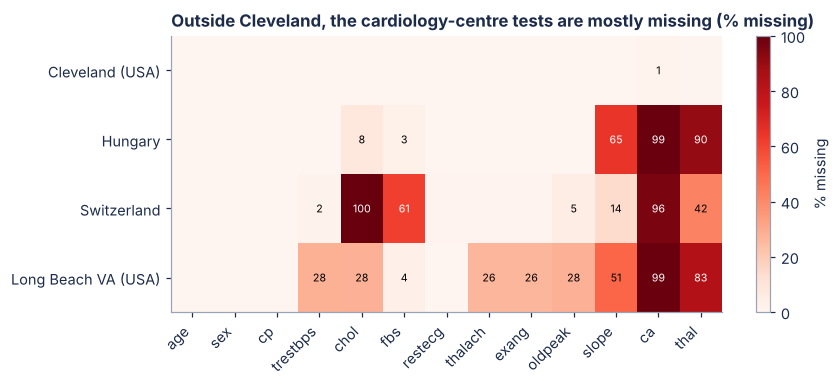

In [3]:
miss = pd.DataFrame({SITES[s]: 100*d[COLS[:-1]].isna().mean() for s, d in DATA.items()})
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(miss.T.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(miss.index))); ax.set_xticklabels(miss.index, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(miss.columns)
for i in range(4):
    for j in range(len(miss.index)):
        v = miss.T.values[i, j]
        if v >= 1: ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "black")
ax.set_title("Outside Cleveland, the cardiology-centre tests are mostly missing (% missing)")
plt.colorbar(im, ax=ax, label="% missing"); plt.tight_layout(); save("missing_by_hospital"); plt.show()

**What this shows.** Outside Cleveland, `ca` (fluoroscopy), `thal` (thallium scan) and `slope` (stress-test ECG) are mostly missing (Hungary: 99% missing `ca`). Even the hospitals in the dataset often didn't run these tests, and a small rural clinic can't run them at all. Prevalence also differs hugely: 36% in Hungary vs 93% in Switzerland. That's a big **distribution shift**, which is exactly what a model meets when it leaves the lab.

## 2. Feature tiers — what can each place actually measure?
| Tier | Where | Measurements |
|---|---|---|
| **Clinic** (our tool) | small rural clinic: interview, blood-pressure cuff, glucometer, point-of-care cholesterol test, 12-lead ECG | age, sex, chest-pain type, resting blood pressure, cholesterol, fasting sugar > 120 mg/dL, resting ECG |
| Hospital | + treadmill stress test | + max heart rate, exercise angina, ST depression, ST slope |
| Full | + cardiology centre imaging | + vessels on fluoroscopy (`ca`), thallium scan (`thal`) |

In [4]:
CLINIC = ["age","sex","cp","trestbps","chol","fbs","restecg"]
HOSPITAL = CLINIC + ["thalach","exang","oldpeak","slope"]
FULL = HOSPITAL + ["ca","thal"]
CATEGORICAL = ["cp","restecg","slope","thal"]

def make_model(features, kind="lr"):
    num = [f for f in features if f not in CATEGORICAL]
    cat = [f for f in features if f in CATEGORICAL]
    prep = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat)])
    clf = {"lr": LogisticRegression(max_iter=2000),
           "rf": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, random_state=0)}[kind]
    return make_pipeline(prep, clf)

## 3. Split, baselines and models
* **Development:** Cleveland, stratified 80/20 split → 242 training patients, 61 internal-test patients.
* **External test:** all of Hungary (294), Switzerland (123) and Long Beach VA (200). The model never sees them.
* **Threshold (decided on training data only):** a screening tool must not miss sick people, so we pick the highest probability cut-off that still catches **≥ 90% of sick patients in 5-fold cross-validation on the training set**. Above it → "refer".

**Baselines** (simplest possible guesses):
1. *Nobody is sick* — the most common class in Cleveland.
2. *Refer everyone* — catches all, overloads the cardiologist.
3. *One-rule* — a single if-then rule learned from the training set (a depth-1 decision tree on clinic measurements).

In [5]:
cle = DATA["cleveland"]
train, test_int = train_test_split(cle, test_size=0.2, stratify=cle["y"], random_state=SEED)
train, test_int = train.reset_index(drop=True), test_int.reset_index(drop=True)
TESTS = {"Cleveland (internal test)": test_int, "Hungary": DATA["hungarian"],
         "Switzerland": DATA["switzerland"], "Long Beach VA": DATA["va"]}
EXTERNAL = ["Hungary", "Switzerland", "Long Beach VA"]
print(f"train: {len(train)} patients ({train.y.mean():.0%} sick) | internal test: {len(test_int)} | external: "
      + ", ".join(f"{k} {len(v)}" for k, v in TESTS.items() if k in EXTERNAL))

CV = StratifiedKFold(5, shuffle=True, random_state=0)

def threshold_for_recall(y, p, target=0.90):
    """Highest cut-off t such that recall(p >= t) >= target."""
    y, p = np.asarray(y), np.asarray(p)
    best = None
    for t in np.sort(np.unique(p)):
        if ((p >= t) & (y == 1)).sum() / (y == 1).sum() >= target:
            best = t
    return best

def fit_with_threshold(features, kind="lr"):
    m = make_model(features, kind)
    cv_p = cross_val_predict(m, train[features], train["y"], cv=CV, method="predict_proba")[:, 1]
    t = threshold_for_recall(train["y"], cv_p)
    m.fit(train[features], train["y"])
    return m, t, cv_p

MODELS = {}
for name, feats, kind in [("Clinic · logistic regression (ours)", CLINIC, "lr"),
                          ("Clinic · random forest", CLINIC, "rf"),
                          ("Hospital · logistic regression", HOSPITAL, "lr"),
                          ("Full 13 · logistic regression", FULL, "lr")]:
    m, t, cv_p = fit_with_threshold(feats, kind)
    MODELS[name] = dict(model=m, t=t, feats=feats, cv_p=cv_p)
    print(f"{name:34s} threshold = {t:.3f}")

stump = make_pipeline(make_model(CLINIC, "lr")[0], DecisionTreeClassifier(max_depth=1, random_state=0))
stump.fit(train[CLINIC], train["y"])
tree = stump[-1]; feat_names = stump[0].get_feature_names_out()
print("One-rule baseline learned from training data: refer if", feat_names[tree.tree_.feature[0]].split("__")[1],
      "is 'yes'" if "cp_" in feat_names[tree.tree_.feature[0]] else "")

train: 242 patients (46% sick) | internal test: 61 | external: Hungary 294, Switzerland 123, Long Beach VA 200
Clinic · logistic regression (ours) threshold = 0.287
Clinic · random forest             threshold = 0.309
Hospital · logistic regression     threshold = 0.276
Full 13 · logistic regression      threshold = 0.235
One-rule baseline learned from training data: refer if cp_4.0 is 'yes'


*`cp_4.0` = **asymptomatic** chest-pain type. Counter-intuitive but well known in this dataset: many patients with blocked arteries report no typical angina.*

In [6]:
rng = np.random.default_rng(SEED)
BOOT = 1000

def metrics(y, pred, prob=None):
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    out = {"missed (FN)": fn, "false alarms (FP)": fp,
           "recall": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1),
           "accuracy": (tp + tn) / len(y)}
    if prob is not None and len(set(y)) > 1:
        out["AUC"] = roc_auc_score(y, prob)
    return out

def boot_ci(y, pred, stat="recall"):
    y, pred = np.asarray(y), np.asarray(pred); vals = []
    for _ in range(BOOT):
        i = rng.integers(0, len(y), len(y)); yy, pp = y[i], pred[i]
        if stat == "recall" and (yy == 1).sum(): vals.append(((pp == 1) & (yy == 1)).sum() / (yy == 1).sum())
        if stat == "specificity" and (yy == 0).sum(): vals.append(((pp == 0) & (yy == 0)).sum() / (yy == 0).sum())
    return np.percentile(vals, [2.5, 97.5])

def predict(name, d):
    M = MODELS[name]; p = M["model"].predict_proba(d[M["feats"]])[:, 1]
    return p, (p >= M["t"]).astype(int)

rows = []
for tname, d in TESTS.items():
    y = d["y"].values
    rows.append({"test set": tname, "method": "Baseline: nobody is sick", **metrics(y, np.zeros(len(y)))})
    rows.append({"test set": tname, "method": "Baseline: refer everyone", **metrics(y, np.ones(len(y)))})
    rows.append({"test set": tname, "method": "Baseline: one-rule (asymptomatic pain)", **metrics(y, stump.predict(d[CLINIC]))})
    for name in MODELS:
        p, pred = predict(name, d)
        lo, hi = boot_ci(y, pred, "recall")
        rows.append({"test set": tname, "method": name, **metrics(y, pred, p), "recall 95% CI": f"{lo:.2f}–{hi:.2f}"})
RESULTS = pd.DataFrame(rows)
display(RESULTS.set_index(["test set", "method"]).round(2).fillna(""))

missed (FN)  false alarms (FP)  recall  specificity  accuracy   AUC recall 95% CI
test set                  method                                                                                                                   
Cleveland (internal test) Baseline: nobody is sick                         28                  0    0.00         1.00      0.54                    
                          Baseline: refer everyone                          0                 33    1.00         0.00      0.46                    
                          Baseline: one-rule (asymptomatic pain)            6                  5    0.79         0.85      0.82                    
                          Clinic · logistic regression (ours)               2                  9    0.93         0.73      0.82  0.87     0.82–1.00
                          Clinic · random forest                            1                  9    0.96         0.73      0.84  0.87     0.89–1.00
                          Hospital · logistic regression                    0                 11    1.00         0.67      0.82  0.94     1.00–1.00
                          Full 13 · logistic regression                     0                 11    1.00         0.67      0.82  0.96     1.00–1.00
Hungary                   Baseline: nobody is sick                        106                  0    0.00         1.00      0.64                    
                          Baseline: refer everyone                          0                188    1.00         0.00      0.36                    
                          Baseline: one-rule (asymptomatic pain)           23                 40    0.78         0.79      0.79                    
                          Clinic · logistic regression (ours)              20                 47    0.81         0.75      0.77  0.84     0.73–0.88
                          Clinic · random forest                           15                 56    0.86         0.70      0.76  0.85     0.79–0.92
                          Hospital · logistic regression                   13                 59    0.88         0.69      0.76  0.89     0.82–0.94
                          Full 13 · logistic regression                    23                 33    0.78         0.82      0.81  0.89     0.70–0.86
Switzerland               Baseline: nobody is sick                        115                  0    0.00         1.00      0.07                    
                          Baseline: refer everyone                          0                  8    1.00         0.00      0.93                    
                          Baseline: one-rule (asymptomatic pain)           19                  2    0.83         0.75      0.83                    
                          Clinic · logistic regression (ours)              13                  3    0.89         0.62      0.87  0.75     0.82–0.94
                          Clinic · random forest                            5                  4    0.96         0.50      0.93  0.82     0.91–0.99
                          Hospital · logistic regression                    9                  5    0.92         0.38      0.89  0.77     0.87–0.97
                          Full 13 · logistic regression                    21                  5    0.82         0.38      0.79  0.73     0.75–0.89
Long Beach VA             Baseline: nobody is sick                        149                  0    0.00         1.00      0.26                    
                          Baseline: refer everyone                          0                 51    1.00         0.00      0.74                    
                          Baseline: one-rule (asymptomatic pain)           41                 23    0.72         0.55      0.68                    
                          Clinic · logistic regression (ours)              10                 37    0.93         0.27      0.76  0.71     0.89–0.97
                          Clinic · random forest                      

## 4. The headline: what happens outside Cleveland?
Sum of missed sick patients (false negatives) and false alarms over the **three never-seen hospitals** (617 patients, 370 of them sick).

,missed (FN),false alarms (FP),recall (pooled)
method,,,
Baseline: nobody is sick,370,0,0.00
Baseline: refer everyone,0,247,1.00
Baseline: one-rule (asymptomatic pain),83,65,0.78
Clinic · logistic regression (ours),43,87,0.88
Clinic · random forest,28,97,0.92
Hospital · logistic regression,39,98,0.89
Full 13 · logistic regression,93,58,0.75


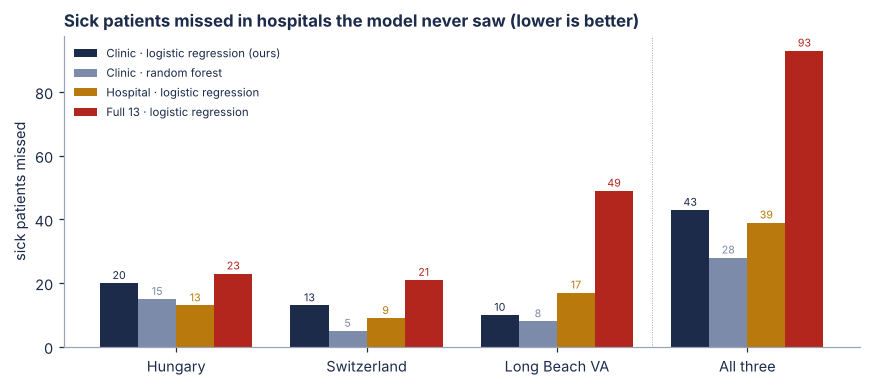

In [7]:
ext = RESULTS[RESULTS["test set"].isin(EXTERNAL)].groupby("method", sort=False)[["missed (FN)", "false alarms (FP)"]].sum()
n_sick_ext = sum(TESTS[k]["y"].sum() for k in EXTERNAL)
ext["recall (pooled)"] = 1 - ext["missed (FN)"] / n_sick_ext
display(ext)

fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(MODELS)
x = np.arange(len(EXTERNAL) + 1); w = 0.2
colors = [INK, "#7d8bab", AMBER, RED]
for k, n in enumerate(names):
    vals = [RESULTS[(RESULTS["test set"] == s) & (RESULTS.method == n)]["missed (FN)"].item() for s in EXTERNAL]
    vals.append(sum(vals))
    bars = ax.bar(x + (k - 1.5) * w, vals, w, label=n, color=colors[k])
    ax.bar_label(bars, fontsize=7, padding=1, color=colors[k])
ax.set_xticks(x); ax.set_xticklabels(EXTERNAL + ["All three"]); ax.set_ylabel("sick patients missed")
ax.axvline(len(EXTERNAL) - 0.5, color=GREY, lw=.6, ls=":")
ax.set_title("Sick patients missed in hospitals the model never saw (lower is better)")
ax.legend(fontsize=7.5, loc="upper left"); plt.tight_layout(); save("missed_external"); plt.show()

**Takeaway.** On Cleveland's own test patients, the 13-measurement model looks perfect (0 missed). In new hospitals it misses **93 sick patients vs 43** for our clinic model — more than twice as many — exactly the opposite of what its internal score suggests. The simple clinic model is also the one a rural clinic can actually use.

*Why logistic regression and not the random forest, which missed even fewer (28)?* The forest also raised more false alarms (97 vs 87), and logistic regression lets us show the clinician **why** a patient was flagged and run the model offline in a phone browser with a few lines of code. Testing an explained forest is on our next-steps list.

## 5. Why does the "full" model break?
When `ca` and `thal` are missing, the pipeline fills them from Cleveland: `ca` with the median, **0 blocked vessels** (the lowest possible value), and `thal` with the most common value, **3 = normal**. In the full model, `ca` is the strongest "sick" signal and `thal = normal` is a strong "healthy" signal. So in Hungary and VA, where these tests weren't done, **every patient silently looks healthier than they are**. Average predicted risk drops far below the real disease rate:

In [8]:
cal = []
for tname, d in TESTS.items():
    r = {"test set": tname, "real % sick": 100 * d.y.mean()}
    for n in ["Clinic · logistic regression (ours)", "Full 13 · logistic regression"]:
        r[f"avg predicted % — {n.split(' ·')[0]}"] = 100 * predict(n, d)[0].mean()
    r["% patients with ca missing"] = 100 * d["ca"].isna().mean()
    cal.append(r)
display(pd.DataFrame(cal).set_index("test set").round(0))

lr_full = MODELS["Full 13 · logistic regression"]["model"]
coef = pd.Series(lr_full[-1].coef_[0], index=lr_full[0].get_feature_names_out())
print(f"Imputed values: ca = {train.ca.median():.0f} vessels, thal = {train.thal.mode()[0]:.0f} (normal)")
print("Full-model coefficients for these inputs:", coef[["num__ca", "cat__thal_3.0", "cat__thal_7.0"]].round(2).to_dict())

,real % sick,avg predicted % — Clinic,avg predicted % — Full 13,% patients with ca missing
test set,,,,
Cleveland (internal test),46.0,43.0,52.0,5.0
Hungary,36.0,36.0,29.0,99.0
Switzerland,93.0,64.0,55.0,96.0
Long Beach VA,74.0,64.0,41.0,99.0


Imputed values: ca = 0 vessels, thal = 3 (normal)
Full-model coefficients for these inputs: {'num__ca': 1.14, 'cat__thal_3.0': -0.55, 'cat__thal_7.0': 0.79}


Lesson for a real deployment: **a model should only use inputs that will actually exist where it is used.** Imputing a missing test result with "normal" is not neutral.

Note that *every* model under-predicts in Switzerland and VA (93% and 74% sick), because those hospitals saw far sicker patients than Cleveland. The *ranking* of patients still works (AUC 0.71–0.84), so a threshold set for high recall still catches most cases — but the raw percentage should not be read as "the chance this patient is sick" in a new place. That's why the app shows **zones**, not a bare percentage.

## 6. Fairness: does it work for women?
All 678 unseen patients (Cleveland internal test + 3 external hospitals), grouped by sex and age.

In [9]:
UNSEEN = pd.concat([d.assign(test_set=k) for k, d in TESTS.items()], ignore_index=True)
OURS = "Clinic · logistic regression (ours)"
UNSEEN["p"], UNSEEN["pred_A"] = predict(OURS, UNSEEN)
UNSEEN["sex_label"] = UNSEEN["sex"].map({0: "women", 1: "men"})
UNSEEN["age_group"] = pd.cut(UNSEEN["age"], [0, 49, 59, 120], labels=["<50", "50–59", "60+"])

def group_table(df, pred_col, by):
    out = []
    for g, d in df.groupby(by, observed=True):
        m = metrics(d["y"], d[pred_col]); lo, hi = boot_ci(d["y"], d[pred_col], "recall")
        out.append({by if isinstance(by, str) else "group": g, "patients": len(d), "sick": int(d.y.sum()),
                    **{k: m[k] for k in ["missed (FN)", "false alarms (FP)", "recall", "specificity"]},
                    "recall 95% CI": f"{lo:.2f}–{hi:.2f}"})
    return pd.DataFrame(out)

display(group_table(UNSEEN, "pred_A", "sex_label").round(2))
display(group_table(UNSEEN, "pred_A", "age_group").round(2))
display(group_table(UNSEEN, "pred_A", ["test_set", "sex_label"]).round(2))

,sex_label,patients,sick,missed (FN),false alarms (FP),recall,specificity,recall 95% CI
0,men,561,366,30,91,0.92,0.53,0.89–0.95
1,women,117,32,15,5,0.53,0.94,0.34–0.69


,age_group,patients,sick,missed (FN),false alarms (FP),recall,specificity,recall 95% CI
0,<50,223,90,24,21,0.73,0.84,0.65–0.82
1,50–59,275,165,19,47,0.88,0.57,0.83–0.93
2,60+,180,143,2,28,0.99,0.24,0.97–1.00


,group,patients,sick,missed (FN),false alarms (FP),recall,specificity,recall 95% CI
0,"(Cleveland (internal test), men)",41,21,1,8,0.95,0.60,0.84–1.00
1,"(Cleveland (internal test), women)",20,7,1,1,0.86,0.92,0.50–1.00
2,"(Hungary, men)",213,94,11,44,0.88,0.63,0.82–0.95
3,"(Hungary, women)",81,12,9,3,0.25,0.96,0.00–0.50
4,"(Long Beach VA, men)",194,146,10,36,0.93,0.25,0.89–0.97
5,"(Long Beach VA, women)",6,3,0,1,1.00,0.67,1.00–1.00
6,"(Switzerland, men)",113,105,8,3,0.92,0.62,0.87–0.97
7,"(Switzerland, women)",10,10,5,0,0.50,0.00,0.20–0.80


**Finding.** The model catches ~92% of sick men but only about **half of sick women** (Hungary: 3 of 12). Two reasons we can see in the data:
* Women are only 32% of the Cleveland training set, and only 18 training women were sick.
* The model leans heavily on "asymptomatic chest pain" and on being male. Women with heart disease in this data more often report *atypical* or *non-anginal* pain, so their risk scores stay low.

Younger patients (<50) are also missed more often (recall ~0.73): age is one of the strongest inputs, so a sick 45-year-old gets a low score.

### Can we fix it? Four options, chosen and tuned **on training data only**
* **A** — one threshold for everyone (current).
* **B** — remove `sex` from the model.
* **C** — reweight training so sick women count as much as sick men.
* **D** — group-specific threshold: rule fixed in advance — *every group must reach ≥ 90% recall in training cross-validation; if a group falls short, lower only that group's threshold until it does.*

training-CV recall with one threshold: {'women': 0.83, 'men': 0.91}
thresholds → women 0.070, men 0.287


,women: recall,women: missed,women: false alarms,men: recall,men: missed,men: false alarms,all: missed,all: false alarms
option,,,,,,,,
A · one threshold,0.53,15,5,0.92,30,91,45,96
B · no sex feature,0.84,5,28,0.87,46,79,51,107
C · reweighting,0.78,7,22,0.90,38,101,45,123
D · group threshold (chosen),0.84,5,24,0.92,30,91,35,115


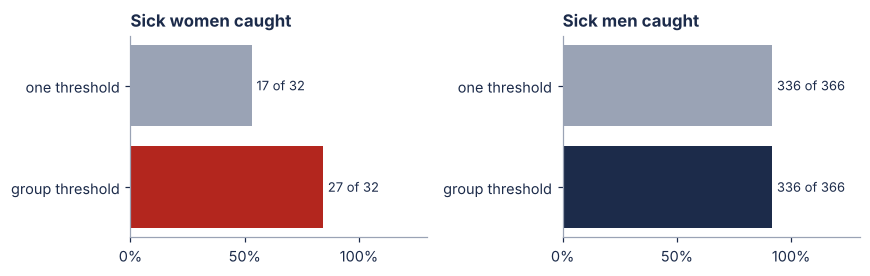

In [10]:
M = MODELS[OURS]; cv_p = M["cv_p"]; t_all = M["t"]
women_tr = (train["sex"] == 0).values
cv_recall = {g: ((cv_p[mask] >= t_all) & (train.y.values[mask] == 1)).sum() / train.y.values[mask].sum()
             for g, mask in [("women", women_tr), ("men", ~women_tr)]}
print("training-CV recall with one threshold:", {k: round(float(v), 2) for k, v in cv_recall.items()})
t_women = threshold_for_recall(train.y.values[women_tr], cv_p[women_tr]) if cv_recall["women"] < 0.9 else t_all
t_men = threshold_for_recall(train.y.values[~women_tr], cv_p[~women_tr]) if cv_recall["men"] < 0.9 else t_all
print(f"thresholds → women {t_women:.3f}, men {t_men:.3f}")

# B: no sex feature
CLINIC_NOSEX = [f for f in CLINIC if f != "sex"]
mB, tB, _ = fit_with_threshold(CLINIC_NOSEX)
UNSEEN["pred_B"] = (mB.predict_proba(UNSEEN[CLINIC_NOSEX])[:, 1] >= tB).astype(int)
# C: reweighting (sex × outcome cells get equal total weight)
w = (len(train) / 4) / train.groupby(["sex", "y"])["y"].transform("size")
cvC = np.zeros(len(train))
for a, b in CV.split(train, train.y):
    mm = make_model(CLINIC); mm.fit(train[CLINIC].iloc[a], train.y.iloc[a], logisticregression__sample_weight=w.iloc[a].values)
    cvC[b] = mm.predict_proba(train[CLINIC].iloc[b])[:, 1]
tC = threshold_for_recall(train.y, cvC)
mC = make_model(CLINIC); mC.fit(train[CLINIC], train.y, logisticregression__sample_weight=w.values)
UNSEEN["pred_C"] = (mC.predict_proba(UNSEEN[CLINIC])[:, 1] >= tC).astype(int)
# D: group-specific threshold
UNSEEN["t_D"] = np.where(UNSEEN.sex == 0, t_women, t_men)
UNSEEN["pred_D"] = (UNSEEN["p"] >= UNSEEN["t_D"]).astype(int)

fx = []
for opt, label in [("A", "A · one threshold"), ("B", "B · no sex feature"), ("C", "C · reweighting"), ("D", "D · group threshold (chosen)")]:
    r = {"option": label}
    for g in ["women", "men"]:
        d = UNSEEN[UNSEEN.sex_label == g]; m = metrics(d.y, d[f"pred_{opt}"])
        r[f"{g}: recall"] = m["recall"]; r[f"{g}: missed"] = m["missed (FN)"]; r[f"{g}: false alarms"] = m["false alarms (FP)"]
    m = metrics(UNSEEN.y, UNSEEN[f"pred_{opt}"])
    r["all: missed"] = m["missed (FN)"]; r["all: false alarms"] = m["false alarms (FP)"]
    fx.append(r)
FIX = pd.DataFrame(fx).set_index("option")
display(FIX.round(2))

fig, axs = plt.subplots(1, 2, figsize=(8, 2.6))
for ax, g in zip(axs, ["women", "men"]):
    n_sick = int(UNSEEN[UNSEEN.sex_label == g].y.sum())
    vals = [n_sick - int(FIX.loc["A · one threshold", f"{g}: missed"]), n_sick - int(FIX.loc["D · group threshold (chosen)", f"{g}: missed"])]
    bars = ax.barh(["one threshold", "group threshold"], [v / n_sick for v in vals], color=[GREY, RED if g == "women" else INK])
    ax.bar_label(bars, labels=[f"{v} of {n_sick}" for v in vals], padding=3, fontsize=8.5)
    ax.set_xlim(0, 1.3); ax.set_xticks([0, .5, 1]); ax.set_xticklabels(["0%", "50%", "100%"])
    ax.set_title(f"Sick {g} caught"); ax.invert_yaxis()
plt.tight_layout(); save("fairness_fix"); plt.show()

**Result.** Option D cuts missed women from 15 to 5 and leaves men unchanged; the price is about 19 extra false alarms among women. For a screening tool where a false alarm means "one extra trip to the district cardiologist" and a miss can mean a heart attack, we think that trade is worth it. B (drop `sex`) also narrows the gap but misses more men.

**Honest caveats.** The women's threshold is estimated from only 18 sick women, and the external test has just 32 sick women, so the confidence intervals are wide. We also saw these results before writing this paragraph, so the comparison of options is not fully blind — the *rule* for D was defined on training data, but our choice to report D as the main option was made after looking. A real deployment would need a new test set with many more women.

## 7. From a probability to an action: three triage zones
* 🟢 **Green** — below the referral threshold (women 0.07, men 0.29): follow up at the clinic, re-check in 12 months or if symptoms change.
* 🟡 **Yellow** — above the threshold: planned referral to the district cardiologist (stress test).
* 🔴 **Red** — risk ≥ the "urgent" cut-off, chosen on training CV so that ≥ 85% of patients above it are sick: refer urgently.

The point of the zones: a clinician can act on them, and the green zone tells them how much they can trust a "low" result.

urgent cut-off = 0.725


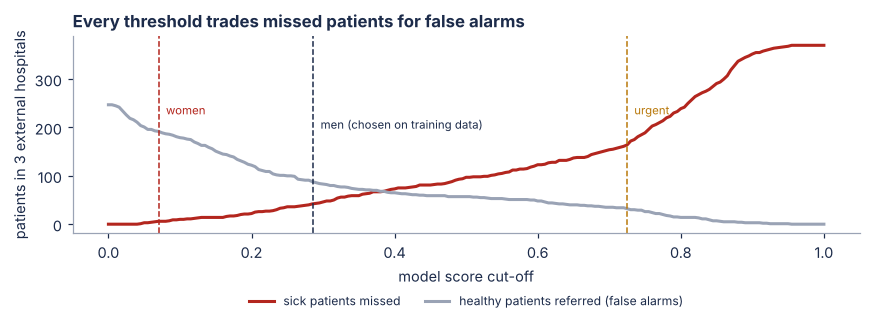

patients  sick  % actually sick
test_set                  zone                                   
Cleveland (internal test) green         21     1              5.0
                          red           15    11             73.0
                          yellow        25    16             64.0
Hungary                   green        143    16             11.0
                          red           61    46             75.0
                          yellow        90    44             49.0
Long Beach VA             green         23    10             43.0
                          red          113    97             86.0
                          yellow        64    42             66.0
Switzerland               green         13     8             62.0
                          red           64    63             98.0
                          yellow        46    44             96.0

,patients,sick,% actually sick
zone,,,
green,200,35,18.0
red,253,217,86.0
yellow,225,146,65.0


In [11]:
def threshold_for_precision(y, p, target=0.85, min_n=10):
    y, p = np.asarray(y), np.asarray(p)
    for t in np.sort(np.unique(p)):
        sel = p >= t
        if sel.sum() >= min_n and y[sel].mean() >= target:
            return t
T_URGENT = threshold_for_precision(train.y, cv_p)
print(f"urgent cut-off = {T_URGENT:.3f}")

UNSEEN["zone"] = np.select([UNSEEN.p >= T_URGENT, UNSEEN.p >= UNSEEN.t_D], ["red", "yellow"], "green")

# The trade-off behind every threshold, on the 3 external hospitals
ext_u = UNSEEN[UNSEEN.test_set.isin(EXTERNAL)]
ts = np.linspace(0, 1, 201)
fn_curve = [int(((ext_u.p < t) & (ext_u.y == 1)).sum()) for t in ts]
fp_curve = [int(((ext_u.p >= t) & (ext_u.y == 0)).sum()) for t in ts]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(ts, fn_curve, color=RED, lw=2, label="sick patients missed")
ax.plot(ts, fp_curve, color=GREY, lw=2, label="healthy patients referred (false alarms)")
for t, lab, c, yy in [(t_women, "women", RED, .92), (t_all, "men (chosen on training data)", INK, .80), (T_URGENT, "urgent", AMBER, .92)]:
    ax.axvline(t, color=c, lw=1, ls="--"); ax.text(t + .01, max(fp_curve) * yy, lab, fontsize=7.5, color=c)
ax.set_xlabel("model score cut-off"); ax.set_ylabel("patients in 3 external hospitals")
ax.set_title("Every threshold trades missed patients for false alarms")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2); plt.tight_layout(); save("threshold_tradeoff"); plt.show()
z = UNSEEN.groupby(["test_set", "zone"]).y.agg(patients="size", sick="sum")
z["% actually sick"] = 100 * z.sick / z.patients
display(z.round(0))
zz = UNSEEN.groupby("zone").y.agg(patients="size", sick="sum"); zz["% actually sick"] = 100 * zz.sick / zz.patients
display(zz.round(0))

Across all unseen patients, a **red** result is right most of the time, and the **green** zone has a much lower disease rate than average. But green is *not* zero-risk: in high-prevalence hospitals (Switzerland, VA) a sizeable share of green patients were sick. The app therefore always says "green ≠ healthy — re-check if symptoms appear."

## 8. Where it fails — real missed patients
Sick patients that the final tool (option D) put in the green zone:

In [12]:
missed = UNSEEN[(UNSEEN.zone == "green") & (UNSEEN.y == 1)].copy()
CP = {1: "typical angina", 2: "atypical angina", 3: "non-anginal", 4: "asymptomatic"}
missed["chest pain"] = missed.cp.map(CP)
print(f"{len(missed)} sick patients put in the green zone out of {int(UNSEEN.y.sum())} sick")
display(missed[["test_set", "age", "sex_label", "chest pain", "trestbps", "chol", "fbs", "restecg", "p"]]
        .sort_values("p").head(12).round(2))
print("\nChest-pain type among missed vs all sick patients (%):")
display(pd.DataFrame({"missed": missed.cp.map(CP).value_counts(normalize=True) * 100,
                      "all sick": UNSEEN[UNSEEN.y == 1].cp.map(CP).value_counts(normalize=True) * 100}).fillna(0).round(0))
print("\nDisease rate by chest-pain type in the Cleveland TRAINING data:")
display(train.groupby(train.cp.map(CP)).y.agg(patients="size", share_sick="mean").round(2))

35 sick patients put in the green zone out of 398 sick


,test_set,age,sex_label,chest pain,trestbps,chol,fbs,restecg,p
317,Hungary,47.0,women,non-anginal,135.0,248.0,1.0,0.0,0.04
332,Hungary,56.0,women,atypical angina,120.0,279.0,0.0,0.0,0.05
270,Hungary,49.0,women,non-anginal,160.0,180.0,0.0,0.0,0.05
273,Hungary,50.0,women,non-anginal,140.0,288.0,0.0,0.0,0.06
351,Hungary,54.0,women,non-anginal,130.0,294.0,0.0,1.0,0.06
355,Switzerland,32.0,men,typical angina,95.0,NaN,NaN,0.0,0.07
252,Hungary,35.0,men,atypical angina,110.0,257.0,0.0,0.0,0.09
251,Hungary,34.0,men,typical angina,140.0,156.0,0.0,0.0,0.10
253,Hungary,36.0,men,atypical angina,120.0,267.0,0.0,0.0,0.11
362,Switzerland,38.0,men,non-anginal,115.0,NaN,0.0,0.0,0.12



Chest-pain type among missed vs all sick patients (%):


,missed,all sick
cp,,
asymptomatic,0.0,78.0
atypical angina,20.0,4.0
non-anginal,66.0,15.0
typical angina,14.0,4.0



Disease rate by chest-pain type in the Cleveland TRAINING data:


,patients,share_sick
cp,,
asymptomatic,117,0.71
atypical angina,42,0.17
non-anginal,64,0.23
typical angina,19,0.32


**Why these are missed.**
1. **Women and young men with atypical or non-anginal pain.** 86% of missed patients reported atypical or non-anginal pain (vs 19% of all sick patients), and none reported "asymptomatic" pain. Most had a normal resting ECG and many were under 50. With only clinic measurements they look like the healthy majority; their disease would show up only on a stress test or angiography. **This is a real limit of screening without a stress test**, not just a model bug.
2. **A data artefact the model copied: "typical angina = low risk".** In Cleveland, only 32% of training patients with *typical* angina had disease, vs 71% with *asymptomatic* pain. This is medically backwards: typical angina is the textbook warning sign. It probably reflects who got sent for angiography in 1980s Cleveland (selection bias), not biology. The model learned it anyway (negative coefficient for `cp_1`), so it under-rates patients with typical angina — e.g. the 32-year-old Swiss man with typical angina in the table above.

**What the app does about it:** it shows a warning for typical angina ("the model under-rates this symptom — use clinical judgement") and always tells the clinician that worsening symptoms mean referral whatever the zone. Retraining on local, recent data is the real fix (see next steps).

## 9. Robustness checks
**(a) Is our single 80/20 split lucky?** We repeat the whole pipeline (split → CV threshold → fit) with 100 different random splits and look at the spread.

model                  Clinic  Full 13
internal recall count  100.00   100.00
                mean     0.90     0.90
                std      0.06     0.07
                min      0.64     0.68
                5%       0.79     0.79
                50%      0.89     0.89
                95%      0.97     1.00
                max      1.00     1.00
external missed count  100.00   100.00
                mean    34.33    81.74
                std      7.05    20.47
                min     16.00    40.00
                5%      25.95    48.00
                50%     33.00    83.00
                95%     44.05   117.05
                max     55.00   129.00

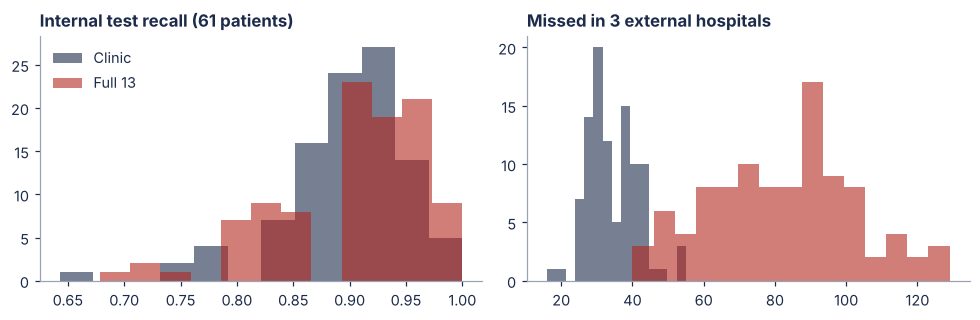

In [13]:
rep = []
ext_all = pd.concat([TESTS[k] for k in EXTERNAL], ignore_index=True)
for s in range(100):
    tr, te = train_test_split(cle, test_size=0.2, stratify=cle.y, random_state=s)
    for nm, feats in [("Clinic", CLINIC), ("Full 13", FULL)]:
        m = make_model(feats)
        cvp = cross_val_predict(m, tr[feats], tr.y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="predict_proba")[:, 1]
        t = threshold_for_recall(tr.y, cvp); m.fit(tr[feats], tr.y)
        rep.append({"seed": s, "model": nm,
                    "internal recall": metrics(te.y, m.predict_proba(te[feats])[:, 1] >= t)["recall"],
                    "external missed": metrics(ext_all.y, m.predict_proba(ext_all[feats])[:, 1] >= t)["missed (FN)"]})
REP = pd.DataFrame(rep)
display(REP.groupby("model")[["internal recall", "external missed"]].describe(percentiles=[.05, .5, .95]).round(2).T)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for nm, c in [("Clinic", INK), ("Full 13", RED)]:
    r = REP[REP.model == nm]
    ax[0].hist(r["internal recall"], bins=12, alpha=.6, color=c, label=nm)
    ax[1].hist(r["external missed"], bins=15, alpha=.6, color=c, label=nm)
ax[0].set_title("Internal test recall (61 patients)"); ax[1].set_title("Missed in 3 external hospitals")
ax[0].legend(); plt.tight_layout(); save("robustness_100_splits"); plt.show()

With only 61 internal test patients, internal recall jumps around a lot from split to split (from 0.64 to 1.00) — another reason not to trust a single internal score. On internal tests the two models look the same (median recall 0.89 each). But in the three external hospitals the clinic model misses a median of **33** sick patients and the full model **83**, and the clinic model misses fewer external patients in **every one of the 100 splits** (printed below). So the headline is not a lucky split.

**(b) What if the clinic can't test cholesterol?** The app lets the clinician leave cholesterol, sugar or ECG blank; the model then fills in the training median. How much does that cost?

In [14]:
abl = []
for label, blank in [("all clinic inputs", []), ("no cholesterol", ["chol"]), ("no cholesterol, no sugar test", ["chol", "fbs"]),
                     ("no cholesterol, no sugar, no ECG", ["chol", "fbs", "restecg"])]:
    d = UNSEEN.copy(); d[blank] = np.nan
    p = MODELS[OURS]["model"].predict_proba(d[CLINIC])[:, 1]
    pred = (p >= d.t_D).astype(int)
    abl.append({"inputs available": label, **{k: v for k, v in metrics(d.y, pred, p).items() if k != "accuracy"}})
display(pd.DataFrame(abl).set_index("inputs available").round(2))
print("Clinic model better than full model (fewer external misses) in",
      int((REP[REP.model == "Clinic"]["external missed"].values < REP[REP.model == "Full 13"]["external missed"].values).sum()), "of 100 splits")

,missed (FN),false alarms (FP),recall,specificity,AUC
inputs available,,,,,
all clinic inputs,35,115,0.91,0.59,0.84
no cholesterol,33,115,0.92,0.59,0.83
"no cholesterol, no sugar test",33,115,0.92,0.59,0.83
"no cholesterol, no sugar, no ECG",33,112,0.92,0.60,0.84


Clinic model better than full model (fewer external misses) in 100 of 100 splits


Leaving cholesterol, sugar and ECG blank barely changes the result (it even misses 2 fewer patients, within noise). The model relies mostly on **age, sex and chest-pain type**. Good news for a poorly equipped clinic — but also a sign that our cholesterol/ECG inputs add little here, and that a better tool would need stronger signals (e.g. a symptom questionnaire or a portable-ECG model).

## 10. What does the model look at? And export for the app
Logistic-regression coefficients (on standardised inputs). Positive = pushes towards "refer".

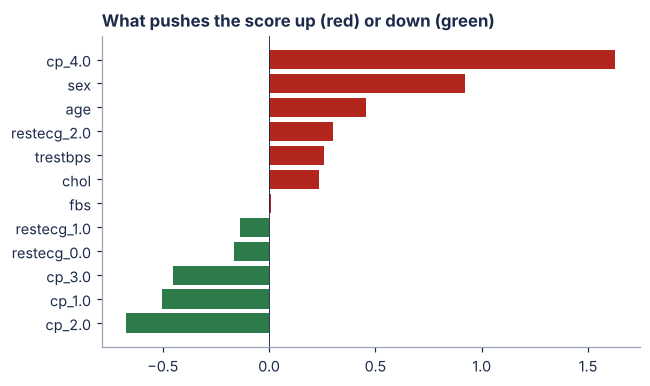

In [15]:
lr = MODELS[OURS]["model"]
coef = pd.Series(lr[-1].coef_[0], index=[n.split("__")[1] for n in lr[0].get_feature_names_out()]).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.barh(coef.index, coef.values, color=np.where(coef.values > 0, RED, GREEN))
ax.axvline(0, color=INK, lw=.6); ax.set_title("What pushes the score up (red) or down (green)")
plt.tight_layout(); save("what_drives_score"); plt.show()

In [16]:
# Export everything the browser app needs to reproduce predictions exactly.
num_cols = [f for f in CLINIC if f not in CATEGORICAL]; cat_cols = [f for f in CLINIC if f in CATEGORICAL]
prep = lr[0]
num_pipe = prep.named_transformers_["num"]; cat_pipe = prep.named_transformers_["cat"]
EXPORT = {
    "features_num": num_cols, "features_cat": cat_cols,
    "num_median": dict(zip(num_cols, num_pipe[0].statistics_.tolist())),
    "num_mean": dict(zip(num_cols, num_pipe[1].mean_.tolist())),
    "num_scale": dict(zip(num_cols, num_pipe[1].scale_.tolist())),
    "cat_mode": dict(zip(cat_cols, cat_pipe[0].statistics_.tolist())),
    "cat_levels": {c: lv.tolist() for c, lv in zip(cat_cols, cat_pipe[1].categories_)},
    "coef": lr[-1].coef_[0].tolist(), "coef_names": list(lr[0].get_feature_names_out()),
    "intercept": float(lr[-1].intercept_[0]),
    "t_women": float(t_women), "t_men": float(t_men), "t_urgent": float(T_URGENT),
    "trained_on": "UCI Heart Disease, Cleveland, 242 patients (80% stratified split, seed 42)",
}
os.makedirs("app", exist_ok=True)
with open("app/model.json", "w") as fh: json.dump(EXPORT, fh, indent=1)

# Performance of the FINAL tool (group thresholds) on unseen patients, shown inside the app
perf = []
for label, d in [(k, UNSEEN[UNSEEN.test_set == k]) for k in TESTS] + \
                [("Women, all unseen", UNSEEN[UNSEEN.sex == 0]), ("Men, all unseen", UNSEEN[UNSEEN.sex == 1])]:
    m = metrics(d.y, d.pred_D)
    perf.append({"set": label, "sick": int(d.y.sum()), "caught": int(d.y.sum()) - m["missed (FN)"],
                 "missed": m["missed (FN)"], "fa": m["false alarms (FP)"]})
with open("app/performance.json", "w") as fh: json.dump(perf, fh, indent=1)
display(pd.DataFrame(perf).set_index("set"))
print("Final tool by age group:")
display(group_table(UNSEEN, "pred_D", "age_group").round(2))
# 5 reference cases for checking that the app gives identical numbers
ref = UNSEEN.sample(5, random_state=1)[CLINIC + ["p"]]
display(ref.round(4))
ref.to_csv("app/reference_cases.csv", index=False)

# Real unseen patients for the app's "try a real patient" buttons, including one the tool gets wrong
def pick(mask, by="p", asc=True):
    return UNSEEN[mask].sort_values(by, ascending=asc).iloc[0]
SITE_NAME = {"Cleveland (internal test)": "Cleveland", "Hungary": "Hungary", "Switzerland": "Switzerland", "Long Beach VA": "Long Beach VA"}
full = UNSEEN.trestbps.notna() & UNSEEN.chol.notna()
examples = [
    ("caught", pick((UNSEEN.zone == "red") & (UNSEEN.y == 1) & (UNSEEN.test_set == "Long Beach VA") & full, "age", True)),
    ("fixed", pick((UNSEEN.sex == 0) & (UNSEEN.y == 1) & (UNSEEN.p >= t_women) & (UNSEEN.p < t_all) & full, "p", False)),
    ("healthy", pick((UNSEEN.zone == "green") & (UNSEEN.y == 0) & (UNSEEN.test_set == "Hungary") & (UNSEEN.sex == 1) & full, "age", False)),
    ("missed", pick((UNSEEN.zone == "green") & (UNSEEN.y == 1) & (UNSEEN.test_set == "Hungary") & (UNSEEN.sex == 0) & full, "p", True)),
]
EX = []
for kind, r in examples:
    EX.append({"kind": kind, "site": SITE_NAME[r.test_set], "sick": int(r.y), "p": round(float(r.p), 4), "zone": r.zone,
               **{f: (None if pd.isna(r[f]) else float(r[f])) for f in CLINIC}})
with open("app/examples.json", "w") as fh: json.dump(EX, fh, indent=1)
STORY = {"ext_sick": int(n_sick_ext),
         "missed_full": int(ext.loc["Full 13 · logistic regression", "missed (FN)"]),
         "missed_ours": int(ext.loc[OURS, "missed (FN)"]),
         "women_sick": int(UNSEEN[UNSEEN.sex == 0].y.sum()),
         "women_caught_before": int(UNSEEN[UNSEEN.sex == 0].y.sum() - FIX.loc["A · one threshold", "women: missed"]),
         "women_caught_after": int(UNSEEN[UNSEEN.sex == 0].y.sum() - FIX.loc["D · group threshold (chosen)", "women: missed"])}
with open("app/story.json", "w") as fh: json.dump(STORY, fh, indent=1)
print(STORY)
display(pd.DataFrame(EX))
print("saved app/model.json")

,sick,caught,missed,fa
set,,,,
Cleveland (internal test),28,27,1,13
Hungary,106,90,16,61
Switzerland,115,107,8,3
Long Beach VA,149,139,10,38
"Women, all unseen",32,27,5,24
"Men, all unseen",366,336,30,91


Final tool by age group:


,age_group,patients,sick,missed (FN),false alarms (FP),recall,specificity,recall 95% CI
0,<50,223,90,19,29,0.79,0.78,0.71–0.88
1,50–59,275,165,16,54,0.90,0.51,0.85–0.95
2,60+,180,143,0,32,1.00,0.14,1.00–1.00


,age,sex,cp,trestbps,chol,fbs,restecg,p
482,66.0,1.0,3.0,110.0,213.0,1.0,2.0,0.43
23,53.0,1.0,3.0,130.0,246.0,1.0,2.0,0.38
353,58.0,0.0,2.0,180.0,393.0,0.0,0.0,0.18
47,54.0,0.0,3.0,110.0,214.0,0.0,0.0,0.03
543,69.0,1.0,3.0,140.0,NaN,NaN,1.0,0.50


{'ext_sick': 370, 'missed_full': 93, 'missed_ours': 43, 'women_sick': 32, 'women_caught_before': 17, 'women_caught_after': 27}


,kind,site,sick,p,zone,age,sex,cp,trestbps,chol,fbs,restecg
0,caught,Long Beach VA,1,0.75,red,46.0,1.0,4.0,134.0,310.0,0.0,0.0
1,fixed,Cleveland,1,0.28,yellow,55.0,0.0,4.0,128.0,205.0,0.0,1.0
2,healthy,Hungary,0,0.26,green,58.0,1.0,2.0,130.0,230.0,0.0,0.0
3,missed,Hungary,1,0.04,green,47.0,0.0,3.0,135.0,248.0,1.0,0.0


saved app/model.json


## Summary
* **Who:** a nurse practitioner or PA at a rural clinic with no cardiologist nearby, deciding whom to refer.
* **In → out:** 7 measurements a rural clinic has → green / yellow / red zone + the main reasons.
* **Beats baselines:** catches far more sick patients than "nobody is sick" and the one-rule baseline, with far fewer false alarms than "refer everyone".
* **Our own question:** the textbook 13-measurement model misses about twice as many sick patients in new hospitals; the clinic-only model travels better.
* **Fairness:** one threshold misses half of sick women; a group threshold fixed on training data cuts missed women from 15 to 5.
* **Where it fails:** young patients and women with atypical chest pain and a normal ECG.

*This project is a prototype and is not medical advice.*